# Validar agregación y estrés: verificaciones de dependencia, retroproyección, severidad y abajo-arriba frente a arriba-abajo

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 02 a 06 de este tema (la agregación, los escenarios y el plan de capital)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- listar las pruebas que validan un modelo de capital económico y una prueba de estrés macro (dossier 05, G.5 y H.7), decir qué pregunta cada una y qué regla da su luz, y recalcular cada una con el motor a partir de los documentos versionados;
- recalcular las ocho pruebas de agregación del caso y la prueba de concordancia de Monte Carlo, y ver la verificación de horizonte y nivel del motor ponerse roja ante una discrepancia plantada;
- recalcular la retroproyección de los satélites a través de 2020, leer por qué los cinco satélites la fallan y ver al motor rechazar una retroproyección cuya ventana de ajuste se filtra en el episodio;
- leer la prueba de signo de las sensibilidades macro, la severidad de cada escenario frente a la crisis financiera global y las reglas del balance estático, y aplicar la regla de abajo-arriba frente a arriba-abajo;
- decir qué significan las luces rojas y ámbar del caso para cuánto se pueden confiar sus números.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests
from riskvalidation.validation import portfolio as port_tests
from riskvalidation.validation import stress as stress_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este cuaderno lee las **filas de prueba** de **C18** (Banco Andino) y los insumos que necesitan.

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (las filas de prueba de agregación y de estrés, las marginales, la banda, el bloque de retroproyección, las filas de severidad), `t-copula-baseline.json` (la banda con estrés de correlación y las dos pruebas de agregación que el escenario base no lleva), `fed-2026-severely-adverse.json`, `eba-2025-adverse.json` y `ngfs-delayed-transition.json` (la severidad de cada escenario) y `models-banco-andino.json` (los coeficientes de los satélites). Una **fila de prueba** es una llamada de prueba del motor guardada como diccionario: `test_id`, `model_id`, `segment`, `statistic`, `metric`, `light` y `extras`.
- **Qué son las luces.** Las pruebas de agregación y de estrés son **umbrales internos de Contraste**, declarados como tales, no umbrales regulatorios ni pruebas de hipótesis: cada función declara su regla en su docstring y registra sus parámetros en `extras["thresholds"]`. El motor no declara cumplimiento.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

baseline_doc = read_json("C18/baseline.json")
baseline = baseline_doc["outputs"]
agg = baseline["aggregation"]
second = read_json("C18/t-copula-baseline.json")
models = read_json("C18/models-banco-andino.json")["fit"]
variants = {name: read_json(f"C18/{name}.json") for name in ("eba-2025-adverse", "fed-2026-severely-adverse", "ngfs-delayed-transition")}
R = np.array(agg["correlation"]["matrix"])
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
band = {(r["method"], r["nu"]): r["capital_clp_m"] for r in agg["band"]}


def committed_row(document, test_id, segment=None):
    return next(t for t in document["tests"] if t["test_id"] == test_id and t.get("segment") == segment)


print("filas de prueba en el documento base:", len(baseline_doc["tests"]), "| en el documento de cópula t:", len(second["tests"]), "| horneado con riskvalidation", baseline_doc["provenance"]["riskvalidation_version"])

carpeta derived encontrada: sí
filas de prueba en el documento base: 17 | en el documento de cópula t: 9 | horneado con riskvalidation 0.9.0


## Método

### Paso 1: las pruebas de agregación

El dossier 05 (G.5) lista qué verificar en un modelo de capital económico: comparar la agregación con la suma simple y la fórmula de la raíz cuadrada, informar la sensibilidad a la elección de cópula, informar las cotas de peor caso, estresar la correlación entre riesgos, comprobar que la asignación suma y el signo de cada beneficio de diversificación, y comprobar que se aplican un horizonte y un nivel de confianza. El motor tiene una prueba para cada una, y las reglas son estas (todo umbral es propio de Contraste):

| Prueba | Regla de la luz |
|---|---|
| `simple_sum_and_variance_covariance` | roja si el agregado supera la suma simple; ámbar si está a más de 10 por ciento del ancla de raíz cuadrada; verde en otro caso |
| `copula_choice_sensitivity` | verde hasta 5 por ciento entre la gaussiana y la mayor diferencia t, ámbar hasta 15 por ciento, roja sobre eso |
| `worst_case_bracket` | roja si alguna fila de la banda queda fuera de la cota inferior y el peor caso |
| `correlation_stress` | roja si el capital baja cuando sube una correlación; ámbar si sube más de 10 por ciento |
| `diversification_sign` | roja si alguna fila diversificada supera la suma simple |
| `horizon_confidence_consistency` | roja si alguna marginal está en otro horizonte o nivel que un año y 99,9 por ciento |
| `euler_additivity` | verde si las contribuciones suman el total dentro de $10^{-6}$ |

La celda siguiente recalcula las siete pruebas a partir de los números versionados (los capitales, la banda, la banda con estrés y la asignación de Euler) e imprime cada luz y estadístico junto a la fila versionada.

In [3]:
# Recalcular las siete pruebas de agregación a partir de los números versionados e imprimir cada una junto a la fila versionada
gaussian, lower, worst = band[("gaussian-copula", None)], band[("lower-bound", None)], band[("worst-case", None)]
t_caps = [(nu, band[("t-copula", nu)]) for nu in agg["nu_set"]["values"]]
between = [v for (method, nu), v in band.items() if method not in ("lower-bound", "worst-case")]
stressed = {(r["method"], r["nu"]): r["capital_clp_m"] for r in second["outputs"]["correlation_stress"]["aggregation"]["band"]}
diversified = [r["diversification_factor"] for r in agg["band"] if r["method"] in ("variance-covariance", "gaussian-copula", "t-copula")]
contributions = np.array([row["contribution_clp_m"] for row in agg["euler"]["allocation"]])
mine = {
    "aggregation.simple_sum_and_variance_covariance": agg_tests.simple_sum_and_variance_covariance(ec, R, gaussian),
    "aggregation.copula_choice_sensitivity": agg_tests.copula_choice_sensitivity(gaussian, t_caps),
    "aggregation.worst_case_bracket": agg_tests.worst_case_bracket(lower, between, worst),
    "aggregation.correlation_stress": agg_tests.correlation_stress(gaussian, stressed[("gaussian-copula", None)]),
    "aggregation.diversification_sign": agg_tests.diversification_sign(diversified),
    "aggregation.horizon_confidence_consistency": agg_tests.horizon_confidence_consistency([1] * 4, [0.999] * 4),
    "portfolio.euler_additivity": port_tests.euler_additivity(contributions, agg["euler"]["es_total_clp_m"], 1e-6),
}
print(f'{"prueba":48s} {"luz":6s} {"estadístico":>12s} | {"versionada":6s} {"estadístico":>12s} igual')
for test_id, result in mine.items():
    row = committed_row(baseline_doc, test_id)
    same = sino(result.light.value == row["light"] and np.isclose(result.statistic, row["statistic"]))
    print(f'{test_id:48s} {result.light.value:6s} {result.statistic:12.4f} | {row["light"]:6s} {row["statistic"]:12.4f} {same}')

prueba                                           luz     estadístico | versionada  estadístico igual
aggregation.simple_sum_and_variance_covariance   green        0.9316 | green        0.9316 sí
aggregation.copula_choice_sensitivity            amber        0.1228 | amber        0.1228 sí
aggregation.worst_case_bracket                   green   704814.1715 | green   704814.1715 sí
aggregation.correlation_stress                   amber        0.1211 | amber        0.1211 sí
aggregation.diversification_sign                 green        0.8394 | green        0.8394 sí
aggregation.horizon_confidence_consistency       green        0.0000 | green        0.0000 sí
portfolio.euler_additivity                       green   709389.9885 | green   709389.9885 sí


Dos de las siete son **ámbar**, y dicen algo. La elección de cópula mueve el capital hasta 12,3 por ciento (la t con $\nu = 4$ frente a la gaussiana), sobre el umbral de 5 por ciento: la respuesta depende de una elección de modelación que ningún dato del caso puede resolver. Y el estrés mercado-crédito a 0,8 sube la fila gaussiana 12,1 por ciento, sobre su umbral de 10 por ciento: la respuesta depende de una correlación que es una convención. Ninguna es una falla del modelo; cada una es una **sensibilidad que el lector debe ver**, por lo cual la banda se muestra completa.

**La prueba de concordancia de Monte Carlo.** En el único caso en que la fórmula de raíz cuadrada es exacta, marginales normales con cópula gaussiana, una simulación debe concordar con ella. `elliptical_mc_agreement(mc_capital, mc_se, vc_capital, z)` comprueba que el capital simulado esté a menos de $z = 3$ errores estándar de la fórmula: es la prueba del simulador mismo. La celda siguiente corre esa simulación como lo hace el pipeline, con marginales normales que tienen los capitales versionados ($\sigma_k = EC_k / z_{0.999}$), un millón de simulaciones y semilla 49 (la semilla del caso, 42, más 7), y compara con la fila versionada. También corre la verificación de horizonte y nivel sobre una discrepancia plantada, una marginal a un horizonte de diez días.

In [4]:
# La prueba de concordancia de Monte Carlo con marginales normales y cópula gaussiana, y la verificación de horizonte sobre una discrepancia plantada
LEVEL = 0.999
z_level = stats.norm.ppf(LEVEL)
normal_ppfs = [(lambda u, s=capital / z_level: s * stats.norm.ppf(u)) for capital in ec]
simulation = cop.copula_aggregate(normal_ppfs, R, "gaussian", None, 0.0, LEVEL, 1_000_000, 49, 100_000)
vc_total = simple.variance_covariance(ec, R)
agreement = agg_tests.elliptical_mc_agreement(simulation.ec, simulation.var_se, vc_total)
row = committed_row(second, "aggregation.elliptical_mc_agreement")
print("capital simulado:", round(simulation.ec, 1), "| error estándar:", round(simulation.var_se, 1), "| ancla de raíz cuadrada:", round(vc_total, 1))
print("estadístico (en errores estándar):", round(agreement.statistic, 4), "| luz:", agreement.light.value, "| versionado:", round(row["statistic"], 4), row["light"])
planted = agg_tests.horizon_confidence_consistency([1.0, 1.0, 10 / 250, 1.0], [0.999] * 4)
print("marginal plantada a diez días: luz:", planted.light.value, "| marginales que discrepan:", planted.extras["offending_indices"], "| sus nombres:", [agg["marginals"][i]["risk"] for i in planted.extras["offending_indices"]])

capital simulado: 526698.9 | error estándar: 1587.1 | ancla de raíz cuadrada: 528106.4
estadístico (en errores estándar): -0.8868 | luz: green | versionado: -0.8868 green
marginal plantada a diez días: luz: red | marginales que discrepan: [2] | sus nombres: ['irrbb']


### Paso 2: la retroproyección de los satélites

Un satélite se valida **fuera de tiempo**: se ajusta con datos que terminan antes de un episodio, se corre a través del episodio con las variables macro **realizadas** y se comparan las tasas de pérdida predichas y realizadas (dossier 05, H.7). El caso ajusta sobre 1985 a 2019 y retroproyecta 2020 T1 a 2025 T4, que contiene el choque de la pandemia. `satellite_backcast(predicted, realised, quarters, fit_end, peak_amber, peak_red, timing_quarters)` compara los máximos:

- **estadístico** la RMSE de lo predicho contra lo realizado; **métrica** el error de tiempo en trimestres (trimestre del máximo predicho menos trimestre del máximo realizado);
- luz **verde** cuando el máximo predicho está a menos de 35 por ciento del máximo realizado en tamaño y a menos de 2 trimestres en tiempo, **ámbar** a menos de 60 por ciento, **roja** en otro caso;
- la luz **`error`** cuando la ventana de ajuste no es estrictamente anterior al episodio: una retroproyección sobre datos con que se ajustó es filtración, y la prueba se niega a correr.

La celda siguiente recalcula la prueba para los cinco tipos de préstamo a partir de los trimestres predichos y realizados versionados, imprime la razón de tamaño y el tiempo, y compara con las filas versionadas. Luego planta una filtración, un ajuste que termina en 2020 T2.

In [5]:
# Recalcular la prueba de retroproyección de cada tipo de préstamo con los trimestres versionados, y plantar una ventana de ajuste que se filtra en el episodio
backcast = {b["fed_loan_type"]: b for b in baseline["backcast"]["per_loan_type"]}
print(f'{"tipo de préstamo":24s} {"razón máx.":>10s} {"tiempo":>7s} {"RMSE":>8s} {"luz":6s} versionada')
for loan_type, block in backcast.items():
    quarters = [q["quarter_end"] for q in block["quarters"]]
    result = stress_tests.satellite_backcast([q["predicted"] for q in block["quarters"]], [q["realised"] for q in block["quarters"]], quarters, block["fit_window"]["end"])
    row = committed_row(baseline_doc, "stress.satellite_backcast", loan_type)
    print(f'{loan_type:24s} {result.extras["peak_ratio"]:10.2f} {result.metric:7.0f} {result.statistic:8.4f} {result.light.value:6s} {row["light"]} (razón {row["extras"]["peak_ratio"]:.2f}, tiempo {row["metric"]:.0f})')
block = backcast["credit-cards"]
leak = stress_tests.satellite_backcast([q["predicted"] for q in block["quarters"]], [q["realised"] for q in block["quarters"]], [q["quarter_end"] for q in block["quarters"]], "2020-06-30")
# el motor escribe su nota en inglés; la tabla da su traducción y falla (KeyError) si el motor cambia el texto
TRADUCCION = {"fit_end 2020-06-30 is not before the first quarter of the episode 2020-03-31: the fit window overlaps the episode it predicts (leakage)": "fit_end 2020-06-30 no es anterior al primer trimestre del episodio 2020-03-31: la ventana de ajuste se traslapa con el episodio que predice (filtración)"}
print("ventana de ajuste que termina 2020-06-30:", leak.light.value, "|", TRADUCCION[leak.notes])

tipo de préstamo         razón máx.  tiempo     RMSE luz    versionada
commercial-industrial          4.55       0   0.0055 red    red (razón 4.55, tiempo 0)
commercial-real-estate        13.14     -14   0.0079 red    red (razón 13.14, tiempo -14)
residential                  252.13     -12   0.0068 red    red (razón 252.13, tiempo -12)
credit-cards                   4.30     -17   0.0371 red    red (razón 4.30, tiempo -17)
other-consumer                 2.09     -21   0.0051 red    red (razón 2.09, tiempo -21)
ventana de ajuste que termina 2020-06-30: error | fit_end 2020-06-30 no es anterior al primer trimestre del episodio 2020-03-31: la ventana de ajuste se traslapa con el episodio que predice (filtración)


Los cinco satélites son **rojos**. Cada uno predice su mayor tasa de pérdida en 2020 T2, el trimestre del choque, desde 2,1 veces el máximo realizado para otro consumo hasta 252 veces para hipotecas residenciales; pero solo los préstamos comerciales e industriales alcanzaron su máximo entonces, y los otros cuatro realizaron sus máximos entre 12 y 21 trimestres después. Los satélites **reaccionan con fuerza a las variables macro realizadas de 2020**, y los castigos realizados de 2020 no los siguieron. Un validador lee esto como un hallazgo sobre los números con estrés del caso: la pérdida de crédito de un escenario severo descansa en satélites que habrían **sobrestimado** la única recesión que cayó dentro de la retroproyección.

El gráfico dibuja las tasas predichas contra las realizadas para los cinco tipos.

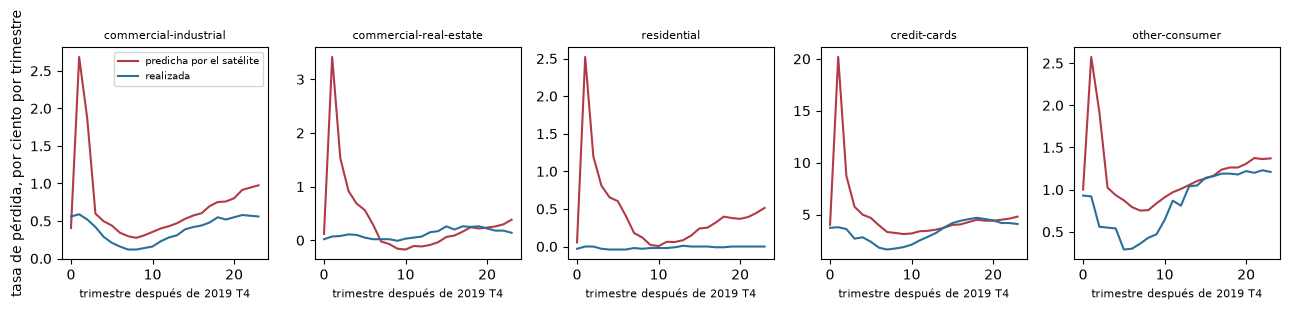

In [6]:
# Dibujar las tasas de pérdida predichas y realizadas de la retroproyección para los cinco tipos de préstamo
fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharex=True)
for ax, (loan_type, block) in zip(axes, backcast.items()):
    ax.plot([q["predicted"] * 100 for q in block["quarters"]], label="predicha por el satélite", color="#b23a48")
    ax.plot([q["realised"] * 100 for q in block["quarters"]], label="realizada", color="#2a6f97")
    ax.set_title(loan_type, fontsize=8)
    ax.set_xlabel("trimestre después de 2019 T4", fontsize=8)
axes[0].set_ylabel("tasa de pérdida, por ciento por trimestre")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

### Paso 3: signos, severidad, las reglas estáticas y abajo-arriba frente a arriba-abajo

**Signos.** `sensitivity_monotonicity(estimates, expected_signs)` cuenta los coeficientes con el signo equivocado respecto del signo declarado **antes** del ajuste (el crecimiento baja la tasa de pérdida: negativo; el desempleo la sube: positivo; el término autorregresivo: positivo), de modo que la pérdida proyectada sea monótona en la severidad de la trayectoria. Es roja cuando algún coeficiente está equivocado.

**Severidad.** `scenario_severity(path_peak, history_peak, is_stress, minimum)` compara la desviación máxima de una variable del escenario con la misma desviación en la crisis financiera global (2008 T1 a 2009 T4): la razón debe ser al menos 0,75, verde si es así y **ámbar** bajo eso (sin rojo: un estrés suave es un hallazgo sobre el escenario, no una falla); el escenario base no es una trayectoria de estrés y es `not_evaluated`.

**Reglas estáticas.** `static_balance_sheet_rules` se corrió en el cuaderno 05.

**Abajo-arriba frente a arriba-abajo.** `bottom_up_vs_top_down(bottom_up, top_down, amber, red)` compara la pérdida con estrés del banco con la de un modelo **retador**: verde dentro de 25 por ciento, ámbar dentro de 50, roja más allá. El caso no hornea un retador arriba-abajo, así que la regla se muestra sobre el único par de totales que dan los documentos y que difieren solo por escenario, la pérdida a tres años de los escenarios adversos de la Reserva Federal y de la EBA, como demostración de la regla y no como comparación con un retador.

La celda siguiente recalcula la prueba de signo a partir de los coeficientes y los signos declarados en el documento de modelos, la severidad de cada escenario a partir de las filas de severidad y la regla de abajo-arriba, y compara con las filas versionadas.

In [7]:
# Recalcular la prueba de signo, la severidad de cada escenario y la regla de abajo-arriba, y comparar con las filas versionadas
estimates, signs, labels = [], [], []
for model in models["satellites"]:
    for coefficient in model["coefficients"]:
        estimates.append(coefficient["estimate"])
        signs.append(coefficient["expected_sign"])
        labels.append(f'{model["fed_loan_type"]}:{coefficient["name"]}')
sign_test = stress_tests.sensitivity_monotonicity(estimates, signs)
row = committed_row(baseline_doc, "stress.sensitivity_monotonicity", None)
print("coeficientes probados:", sign_test.n, "| con signo equivocado:", int(sign_test.statistic), "| luz:", sign_test.light.value, "| versionada:", row["light"], int(row["statistic"]))
for index in sign_test.extras["offending_indices"]:
    print(f"  {labels[index]:46s} estimación {estimates[index]:+.5f}, esperado {signs[index]}")
print(f'{"escenario":28s} {"variable":18s} {"máx.":>6s} {"crisis":>7s} {"razón":>6s} luz        versionada')
for name, document in {"baseline": baseline_doc, **variants}.items():
    for severity in document["outputs"]["severity"]["rows"]:
        result = stress_tests.scenario_severity(severity["path_peak_deviation"], severity["history_peak_deviation"], severity["is_stress"])
        row = committed_row(document, "stress.scenario_severity", severity["maps_to_regressor"])
        print(f'{name:28s} {severity["maps_to_regressor"]:18s} {severity["path_peak_deviation"]:6.2f} {severity["history_peak_deviation"]:7.2f} {"-" if result.statistic != result.statistic else format(result.statistic, ".3f"):>6s} {result.light.value:10s} {row["light"]}')
totals = {name: sum(r["total"] for r in document["outputs"]["losses"]["scenario_losses"]) for name, document in variants.items()}
demo = stress_tests.bottom_up_vs_top_down(totals["eba-2025-adverse"], totals["fed-2026-severely-adverse"])
print("demostración de la regla, pérdida adversa EBA sobre pérdida severa de la Reserva Federal menos 1:", round(demo.statistic, 4), "| luz:", demo.light.value, "| umbrales:", demo.extras["thresholds"])

coeficientes probados: 30 | con signo equivocado: 6 | luz: red | versionada: red 6
  commercial-industrial:real_gdp_growth_lag0     estimación +0.00069, esperado negative
  commercial-real-estate:real_gdp_growth_lag1    estimación +0.00005, esperado negative
  residential:real_gdp_growth_lag0               estimación +0.00005, esperado negative
  residential:real_gdp_growth_lag1               estimación +0.00006, esperado negative
  credit-cards:real_gdp_growth_lag0              estimación +0.00038, esperado negative
  credit-cards:real_gdp_growth_lag1              estimación +0.00057, esperado negative
escenario                    variable             máx.  crisis  razón luz        versionada
baseline                     unemployment_rate    0.20    5.10      - not_evaluated not_evaluated
baseline                     real_gdp_growth      1.10   11.00      - not_evaluated not_evaluated
baseline                     prime_rate           1.00    4.20      - not_evaluated not_evaluated
eba

## Resultados

La celda siguiente cuenta cada prueba del caso por luz, con las filas versionadas de los documentos base y de agregación, para que el lector vea toda la batería de una vez.

In [8]:
# Contar las filas de prueba versionadas de C18 por prueba y luz en los documentos base y de cópula t
from collections import Counter

rows = baseline_doc["tests"] + [t for t in second["tests"] if t["test_id"] in ("aggregation.elliptical_mc_agreement", "aggregation.rosenberg_schuermann_reference")]
by_light = Counter(t["light"] for t in rows)
print("filas versionadas:", len(rows), "| por luz:", dict(by_light))
for test_id in sorted({t["test_id"] for t in rows}):
    print(f'{test_id:48s}', dict(Counter(t["light"] for t in rows if t["test_id"] == test_id)))

filas versionadas: 19 | por luz: {'green': 8, 'amber': 2, 'red': 6, 'not_evaluated': 3}
aggregation.copula_choice_sensitivity            {'amber': 1}
aggregation.correlation_stress                   {'amber': 1}
aggregation.diversification_sign                 {'green': 1}
aggregation.elliptical_mc_agreement              {'green': 1}
aggregation.horizon_confidence_consistency       {'green': 1}
aggregation.rosenberg_schuermann_reference       {'green': 1}
aggregation.simple_sum_and_variance_covariance   {'green': 1}
aggregation.worst_case_bracket                   {'green': 1}
portfolio.euler_additivity                       {'green': 1}
stress.satellite_backcast                        {'red': 5}
stress.scenario_severity                         {'not_evaluated': 3}
stress.sensitivity_monotonicity                  {'red': 1}
stress.static_balance_sheet_rules                {'green': 1}


- **Toda prueba de agregación recalculada desde los números versionados da la luz y el estadístico versionados**: suma simple y regla de raíz cuadrada verde (el agregado es 93,2 por ciento del ancla), intervalo del peor caso verde, signo de diversificación verde, horizonte y nivel verde, aditividad de Euler verde, y las dos luces ámbar, elección de cópula (12,3 por ciento frente a un umbral de 5 por ciento) y estrés de correlación (12,1 por ciento frente a 10 por ciento).
- **La prueba de concordancia de Monte Carlo es verde en una simulación nueva** que reproduce la fila versionada: el capital con marginales normales y cópula gaussiana es 526.699 con un error estándar de 1.587, 0,89 errores estándar bajo el ancla de raíz cuadrada de 528.106 (umbral: 3). Una marginal plantada a diez días pone roja la verificación de horizonte y nombra el riesgo de tasa de interés.
- **Los cinco satélites son rojos en la retroproyección.** El máximo predicho es 2,1 a 252 veces el realizado (4,55 para comerciales e industriales, 13,14 para bienes raíces comerciales, 252,13 para residencial, 4,30 para tarjetas y 2,09 para otro consumo); solo los comerciales e industriales alcanzaron su máximo en el trimestre predicho, y los otros lo alcanzaron 12 a 21 trimestres después. Una ventana de ajuste que termina en 2020 T2 se rechaza con la luz `error`.
- **Seis de los 30 coeficientes tienen el signo equivocado**: los coeficientes del crecimiento del PIB de comerciales e industriales (rezago 0), bienes raíces comerciales (rezago 1), residencial (rezagos 0 y 1) y tarjetas de crédito (rezagos 0 y 1) son levemente positivos donde se declaró un signo negativo antes del ajuste. La prueba de signo es roja.
- **La severidad es mixta.** El escenario severamente adverso de la Reserva Federal pasa en desempleo (1,078) y tasa prime (0,929) y es ámbar en crecimiento del PIB (0,582 de la crisis); el adverso de la EBA es ámbar en crecimiento del PIB (0,711) y verde en lo demás; toda variable de la NGFS es ámbar (0,04 a 0,14), porque el choque de transición tardía es un choque de política climática mucho más suave en términos macro que la crisis; el escenario base es `not_evaluated`.
- **La regla de abajo-arriba se muestra, no se corre con un retador**: la pérdida a tres años adversa de la EBA es 7,3 por ciento mayor que la severa de la Reserva Federal, verde frente a los umbrales de 25 y 50 por ciento.
- **En las 19 filas de prueba versionadas: 8 verdes, 2 ámbar, 6 rojas y 3 no evaluadas.** Las rojas están todas en la capa de estrés, y el principal del caso dice que su pérdida de crédito con estrés descansa en satélites que fallan su propia retroproyección.

Lo que este cuaderno no muestra: los umbrales son los internos de Contraste, así que una luz es una lectura de esa política y no un veredicto regulatorio; el caso no tiene un modelo retador, así que abajo-arriba frente a arriba-abajo se demostró y no se realizó; y las luces dicen que los satélites son débiles, no qué daría un modelo mejor.

## Resumen

- El motor tiene una prueba para cada verificación del dossier 05: siete para la agregación (más la concordancia de Monte Carlo y la referencia publicada) y seis para el estrés, cada una con una regla declarada y umbrales que son de Contraste, no del regulador.
- Recalculadas desde los números versionados, toda prueba de agregación y las pruebas de retroproyección, signo y severidad dan la luz y el estadístico versionados; la prueba de concordancia de Monte Carlo es verde en una simulación nueva.
- Las dos luces ámbar de agregación son sensibilidades (la elección de cópula y el estrés de correlación) que la banda existe para mostrar; las luces rojas son sobre los **satélites**: los cinco fallan su retroproyección y seis coeficientes tienen el signo equivocado.
- Las pruebas rechazan lo que deben: un horizonte discrepante es rojo, una ventana de ajuste que se filtra en el episodio es `error`, y un escenario más suave que la crisis financiera global es ámbar.
- La consecuencia no es que el caso esté equivocado, sino que su pérdida de crédito con estrés descansa en satélites que su propia batería de validación marca en rojo.

**Qué probar a continuación.** Reemplaza los umbrales ámbar y rojo de una prueba por los tuyos y mira qué luces cambian; luego sigue con el cuaderno 08, el estado del arte, que pone la agregación y los satélites del caso junto a los modelos supervisores y las medidas de riesgo de modelo.

## Referencias

- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Dossier 05 de la investigación persistida de Contraste (G.5, pruebas de validación de un modelo de capital económico, y H.7, qué prueban los validadores en un modelo de estrés), resumido en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/aggregation-api.md` y `docs/contracts/engine/stress-api.md` (las pruebas de validación y sus reglas) y `docs/design/features/c18/validation.md`.